# Formative 2 – Task 1: Data Merge & Feature Engineering
**Goal:** merge `customer_social_profiles` and `customer_transactions` into one dataset that can predict **which product category a customer will buy** (`product_category`).

**Notebook map:** 1 Load & audit → 2 Cleaning → 3 Merge strategy & justification → 4 Post-merge validation → 5 Feature engineering → 6 EDA (6 labelled plots) → 7 Signal check & modelling notes → 8 Save outputs

## 1. Load & audit the raw data

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.merge_pipeline import *
sns.set_theme(style='whitegrid', palette='deep'); plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold'})
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)

raw_t = pd.read_excel(RAW/'customer_transactions.xlsx')
raw_s = pd.read_excel(RAW/'customer_social_profiles.xlsx')
print('transactions:', raw_t.shape, '| social profiles:', raw_s.shape)
display(raw_t.head(3)); display(raw_s.head(3))

transactions: (150, 6) | social profiles: (155, 5)


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive


In [2]:
audit = pd.DataFrame({
  'dataset':['transactions','social'],
  'rows':[len(raw_t), len(raw_s)],
  'unique_customers':[raw_t.customer_id_legacy.nunique(), raw_s.customer_id_new.nunique()],
  'exact_duplicate_rows':[raw_t.duplicated().sum(), raw_s.duplicated().sum()],
  'missing_cells':[raw_t.isna().sum().sum(), raw_s.isna().sum().sum()],
  'id_format':['int (e.g. 151)','str (e.g. "A178")']})
display(audit)
print('Variable types\n', pd.concat([raw_t.dtypes.rename('transactions'), raw_s.dtypes.rename('social')], axis=1).fillna('-'))
print('\nMissing values per column:'); print(raw_t.isna().sum()[lambda x:x>0].to_string())
ids_t = set(raw_t.customer_id_legacy); ids_s = set(raw_s.customer_id_new.str[1:].astype(int))
print(f'\nCustomers only in transactions: {len(ids_t-ids_s)} | only in social: {len(ids_s-ids_t)} | in both: {len(ids_t&ids_s)}')
print('Social rows per customer (raw):', raw_s.groupby('customer_id_new').size().value_counts().sort_index().to_dict())

,dataset,rows,unique_customers,exact_duplicate_rows,missing_cells,id_format
0,transactions,150,75,0,10,int (e.g. 151)
1,social,155,84,5,0,"str (e.g. ""A178"")"


Variable types
                            transactions   social
customer_id_legacy                int64        -
transaction_id                    int64        -
purchase_amount                   int64        -
purchase_date            datetime64[us]        -
product_category                    str        -
customer_rating                 float64        -
customer_id_new                       -      str
social_media_platform                 -      str
engagement_score                      -    int64
purchase_interest_score               -  float64
review_sentiment                      -      str

Missing values per column:
customer_rating    10

Customers only in transactions: 14 | only in social: 23 | in both: 61
Social rows per customer (raw): {1: 43, 2: 22, 3: 14, 4: 1, 5: 3, 7: 1}


### Audit findings (what could silently break a naive merge)
| # | Finding | Why it matters |
|---|---|---|
| 1 | **Key formats differ** – `customer_id_legacy` = `151` vs `customer_id_new` = `"A151"` | A direct join matches **zero** rows |
| 2 | **Social table is not 1 row/customer** – 155 rows for 84 customers (up to 7 rows each, different platforms/scores) | A row-level join *fans out* and duplicates transactions |
| 3 | **5 exact duplicate rows** in the social table | Would double-count those customers' engagement |
| 4 | **10 missing `customer_rating`** values (6.7 %) | Must be handled, not dropped blindly |
| 5 | **Partial key overlap** – only 61 customers appear in both files | Inner join would discard 33 transactions silently |

## 2. Cleaning

In [3]:
t_clean = load_and_clean_transactions()
s_clean = load_and_clean_social()
print(f"Social exact duplicates dropped: {s_clean.attrs['n_exact_duplicates_dropped']}")
print(f"Ratings imputed with global median ({raw_t.customer_rating.median()}): {t_clean.rating_missing.sum()} rows  (flagged in `rating_missing`)")
print('IDs normalised ->', raw_s.customer_id_new.iloc[0], '->', s_clean.customer_id.iloc[0], '| dtypes:'); print(t_clean.dtypes.to_string())
assert t_clean.isna().sum().sum()==0 and s_clean.isna().sum().sum()==0 and not s_clean.duplicated().any()
print('\n✔ No nulls / duplicates remain; categorical text trimmed / casing standardised; dates parsed to datetime')

Social exact duplicates dropped: 5
Ratings imputed with global median (3.0): 10 rows  (flagged in `rating_missing`)
IDs normalised -> A178 -> 178 | dtypes:
customer_id                  int64
transaction_id               int64
purchase_amount              int64
purchase_date       datetime64[us]
product_category               str
customer_rating            float64
rating_missing               int64

✔ No nulls / duplicates remain; categorical text trimmed / casing standardised; dates parsed to datetime


**Imputation choice:** the median (3.0) is robust and, because ratings are roughly symmetric (skew ≈ −0.08), does not distort the distribution. Instead of hiding the gap, `rating_missing` keeps the information that the value was absent.

## 3. Merge strategy and justification

In [4]:
# (a) What a NAIVE merge would do (after fixing only the ID format)
naive = t_clean.merge(s_clean, on='customer_id', how='inner')
print(f'Naive row-level inner join: {len(naive)} rows  (transactions had {len(t_clean)}; matched txns = {t_clean.customer_id.isin(s_clean.customer_id).sum()})')
print(f'  -> {len(naive) - t_clean.customer_id.isin(s_clean.customer_id).sum()} phantom rows created, and {(~t_clean.customer_id.isin(s_clean.customer_id)).sum()} real transactions lost\n')

# (b) Our approach: aggregate social to ONE row per customer, then LEFT join onto transactions
s_agg = aggregate_social(s_clean)
print('Aggregated social table:', s_agg.shape, '| customer_id unique:', s_agg.customer_id.is_unique)
merged = t_clean.merge(s_agg, on='customer_id', how='left', validate='many_to_one', indicator=True)
print(merged['_merge'].value_counts().to_string())

Naive row-level inner join: 213 rows  (transactions had 150; matched txns = 117)
  -> 96 phantom rows created, and 33 real transactions lost

Aggregated social table: (84, 14) | customer_id unique: True
_merge
both          117
left_only      33
right_only      0


**Why this join:**
* **Grain = one transaction.** The target (`product_category`) is a property of a transaction, so the transaction table is the *left* table.
* **Aggregate first, join second.** Collapsing social activity to one row per customer (mean/max engagement & interest, platform count, dominant platform, sentiment mix) turns a one-to-many join into a clean **many-to-one** join (`validate='many_to_one'` enforces it) – row count cannot inflate.
* **Left (not inner) join + `has_social_profile` flag.** Keeps all 150 transactions for the merged deliverable and makes the 33 un-matched ones explicit. The model-ready file then uses only the 117 transactions that genuinely have social context – no fabricated social values.

## 4. Post-merge validation checks

In [5]:
final = build()[3]
checks = {
 'Row count preserved (150 = 150)'            : len(final) == len(t_clean),
 'transaction_id still unique'                : final.transaction_id.is_unique,
 'No fan-out vs. naive join'                  : len(final) < len(naive),
 'Matched txns = txns whose customer has social': final.has_social_profile.sum() == t_clean.customer_id.isin(s_agg.customer_id).sum(),
 'Unmatched rows have NaN social, matched have none': final.loc[final.has_social_profile==0,'avg_engagement'].isna().all() and final.loc[final.has_social_profile==1,'avg_engagement'].notna().all(),
 'Target has no nulls'                        : final.product_category.notna().all(),
 'Categorical ranges valid'                   : final.avg_purchase_interest.dropna().between(1,5).all() and final.avg_engagement.dropna().between(50,99).all(),
}
for k,v in checks.items(): print('✔' if v else '✘', k)
assert all(checks.values())
# spot-check: recompute one customer by hand
cid = int(final.loc[final.has_social_profile==1].groupby('customer_id').size().sort_values().index[-1]); man = s_clean[s_clean.customer_id==cid]
row = final[final.customer_id==cid].iloc[0]
print(f'\nSpot-check customer {cid}: manual avg_engagement={man.engagement_score.mean():.4f} vs merged={row.avg_engagement:.4f}')
assert abs(man.engagement_score.mean()-row.avg_engagement)<1e-3

✔ Row count preserved (150 = 150)
✔ transaction_id still unique
✔ No fan-out vs. naive join
✔ Matched txns = txns whose customer has social
✔ Unmatched rows have NaN social, matched have none
✔ Target has no nulls
✔ Categorical ranges valid

Spot-check customer 187: manual avg_engagement=85.6667 vs merged=85.6667


## 5. Feature engineering

In [6]:
feat = pd.DataFrame([
 ('Original – transactions','purchase_amount, customer_rating, purchase_date, product_category (target)'),
 ('Original – social (aggregated)','n_social_records, n_platforms, avg/max_engagement, avg/max_purchase_interest'),
 ('Social – derived','top_platform (highest total engagement), share_positive/neutral/negative, avg_sentiment_score (+1/0/−1), dominant_sentiment, engagement_x_interest'),
 ('Temporal','purchase_month, purchase_dayofweek, is_weekend'),
 ('Monetary','amount_tier (Low/Mid/High terciles)'),
 ('Customer history (leakage-safe, earlier txns only)','prior_txn_count, prior_avg_amount, prior_avg_rating, days_since_prev_txn, prev_category, is_repeat_customer'),
 ('Data-quality flags','rating_missing, has_social_profile')], columns=['Group','Features'])
pd.set_option('display.max_colwidth', 200); display(feat)
print('Final shape:', final.shape)
display(final.head(5).T)

,Group,Features
0,Original – transactions,"purchase_amount, customer_rating, purchase_date, product_category (target)"
1,Original – social (aggregated),"n_social_records, n_platforms, avg/max_engagement, avg/max_purchase_interest"
2,Social – derived,"top_platform (highest total engagement), share_positive/neutral/negative, avg_sentiment_score (+1/0/−1), dominant_sentiment, engagement_x_interest"
3,Temporal,"purchase_month, purchase_dayofweek, is_weekend"
4,Monetary,amount_tier (Low/Mid/High terciles)
5,"Customer history (leakage-safe, earlier txns only)","prior_txn_count, prior_avg_amount, prior_avg_rating, days_since_prev_txn, prev_category, is_repeat_customer"
6,Data-quality flags,"rating_missing, has_social_profile"


Final shape: (150, 31)


,0,1,2,3,4
customer_id,151,192,114,171,160
transaction_id,1001,1002,1003,1004,1005
purchase_amount,408,332,442,256,64
purchase_date,2024-01-01 00:00:00,2024-01-02 00:00:00,2024-01-03 00:00:00,2024-01-04 00:00:00,2024-01-05 00:00:00
product_category,Sports,Electronics,Electronics,Clothing,Clothing
customer_rating,2.3,4.2,2.1,2.8,1.3
rating_missing,0,0,0,0,0
n_social_records,3.0,1.0,1.0,NaN,3.0
n_platforms,2.0,1.0,1.0,NaN,3.0
avg_engagement,71.6667,60.0,87.0,NaN,72.6667


**Leakage note.** History features use `shift()` + expanding statistics, so a transaction only sees *strictly earlier* purchases by the same customer. `purchase_amount` and `customer_rating` describe the purchase itself and are only known *after* the sale – they are kept in the dataset (the brief asks to capture features from both sources) but flagged for you to decide whether to use them in the final model (see Section 7).

## 6. Exploratory Data Analysis

In [7]:
print('Summary statistics – merged numeric features (model-ready subset)')
ready = final[final.has_social_profile==1]
num_cols = ['purchase_amount','customer_rating','avg_engagement','avg_purchase_interest','avg_sentiment_score','n_platforms','n_social_records']
display(ready[num_cols].describe().round(2).T)
print('\nVariable types:'); print(final.dtypes.value_counts().to_string())

Summary statistics – merged numeric features (model-ready subset)


,count,mean,std,min,25%,50%,75%,max
purchase_amount,117.0,287.91,120.08,62.0,183.00,280.00,397.0,495.0
customer_rating,117.0,3.11,1.20,1.0,2.10,3.20,4.1,5.0
avg_engagement,117.0,74.15,12.67,50.0,66.50,77.00,83.0,99.0
avg_purchase_interest,117.0,3.08,1.04,1.0,2.67,3.13,3.7,4.8
avg_sentiment_score,117.0,0.10,0.75,-1.0,-0.50,0.00,1.0,1.0
n_platforms,117.0,1.60,0.73,1.0,1.00,1.00,2.0,4.0
n_social_records,117.0,1.82,0.90,1.0,1.00,2.00,2.0,4.0



Variable types:
float64           15
int64              8
str                5
int32              2
datetime64[us]     1


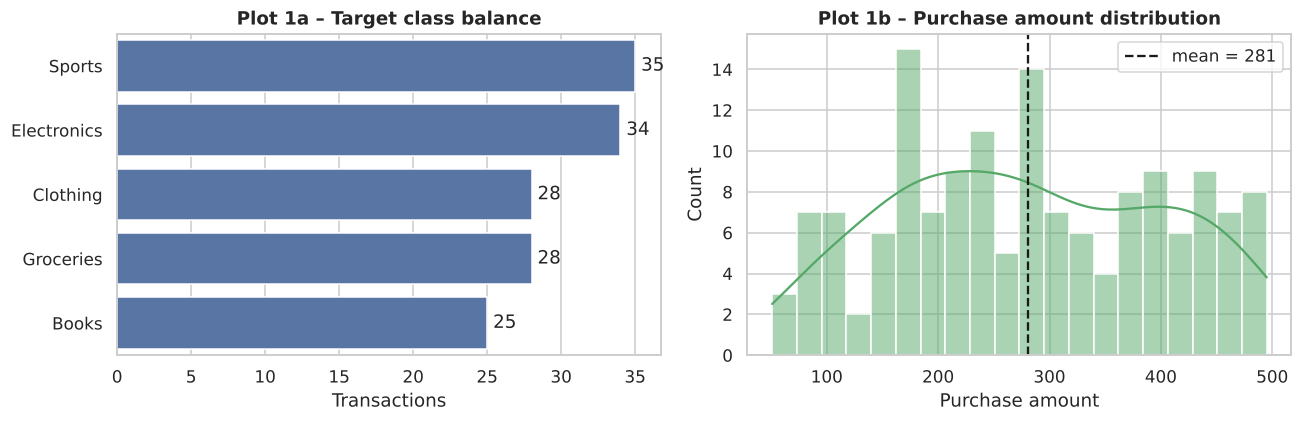

In [8]:
# PLOT 1 – target distribution + amount distribution
fig, ax = plt.subplots(1,2, figsize=(12,4))
order = final.product_category.value_counts().index
sns.countplot(data=final, y='product_category', order=order, ax=ax[0], color='#4C72B0')
for p in ax[0].patches: ax[0].annotate(int(p.get_width()), (p.get_width()+.4, p.get_y()+p.get_height()/2), va='center')
ax[0].set(title='Plot 1a – Target class balance', xlabel='Transactions', ylabel='')
sns.histplot(final.purchase_amount, bins=20, kde=True, ax=ax[1], color='#55A868')
ax[1].axvline(final.purchase_amount.mean(), color='k', ls='--', label=f'mean = {final.purchase_amount.mean():.0f}')
ax[1].set(title='Plot 1b – Purchase amount distribution', xlabel='Purchase amount'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG/'eda1_target_amount.png'); plt.show()

**Interpretation – Plot 1.** The five classes are well balanced (Sports 35 → Books 25, imbalance ratio ≈ 1.4), so plain accuracy is a fair metric and no resampling is needed; macro-F1 should still be reported. Purchase amounts are close to uniform between ≈ 50 and ≈ 500 (skew ≈ 0.06) with no heavy tail – no transformation required.

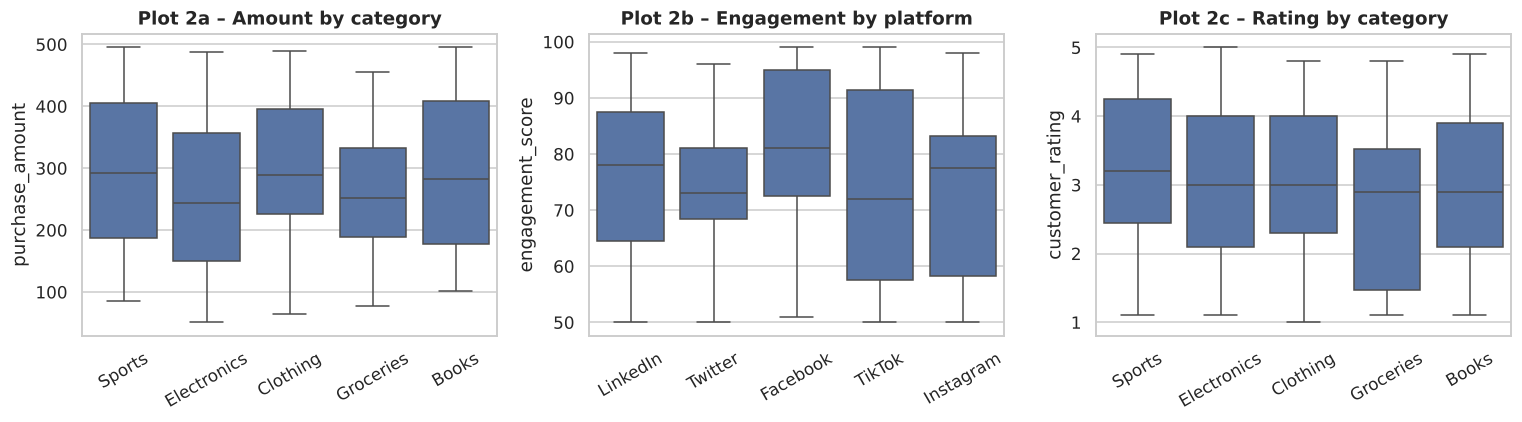

{'purchase_amount': 0, 'customer_rating': 0} {'engagement_score': 0, 'purchase_interest_score': 0}


In [9]:
# PLOT 2 – outlier check (IQR boxplots)
fig, ax = plt.subplots(1,3, figsize=(14,4))
sns.boxplot(data=final, x='product_category', y='purchase_amount', order=order, ax=ax[0]); ax[0].tick_params(axis='x', rotation=30)
ax[0].set(title='Plot 2a – Amount by category', xlabel='')
sns.boxplot(data=s_clean, x='social_media_platform', y='engagement_score', ax=ax[1]); ax[1].tick_params(axis='x', rotation=30)
ax[1].set(title='Plot 2b – Engagement by platform', xlabel='')
sns.boxplot(data=final, x='product_category', y='customer_rating', order=order, ax=ax[2]); ax[2].tick_params(axis='x', rotation=30)
ax[2].set(title='Plot 2c – Rating by category', xlabel='')
plt.tight_layout(); plt.savefig(FIG/'eda2_outliers.png'); plt.show()
def n_out(s): q1,q3=s.quantile([.25,.75]); i=q3-q1; return int(((s<q1-1.5*i)|(s>q3+1.5*i)).sum())
print({c: n_out(final[c]) for c in ['purchase_amount','customer_rating']}, {c: n_out(s_clean[c]) for c in ['engagement_score','purchase_interest_score']})

**Interpretation – Plot 2.** The IQR rule flags **0 outliers** in every numeric column, so no capping or removal is applied. Medians and spreads look alike across categories and platforms – an early hint that no single raw variable separates the classes strongly (confirmed in Section 7). Facebook shows the highest average engagement (≈ 81 vs ≈ 73–77 elsewhere).

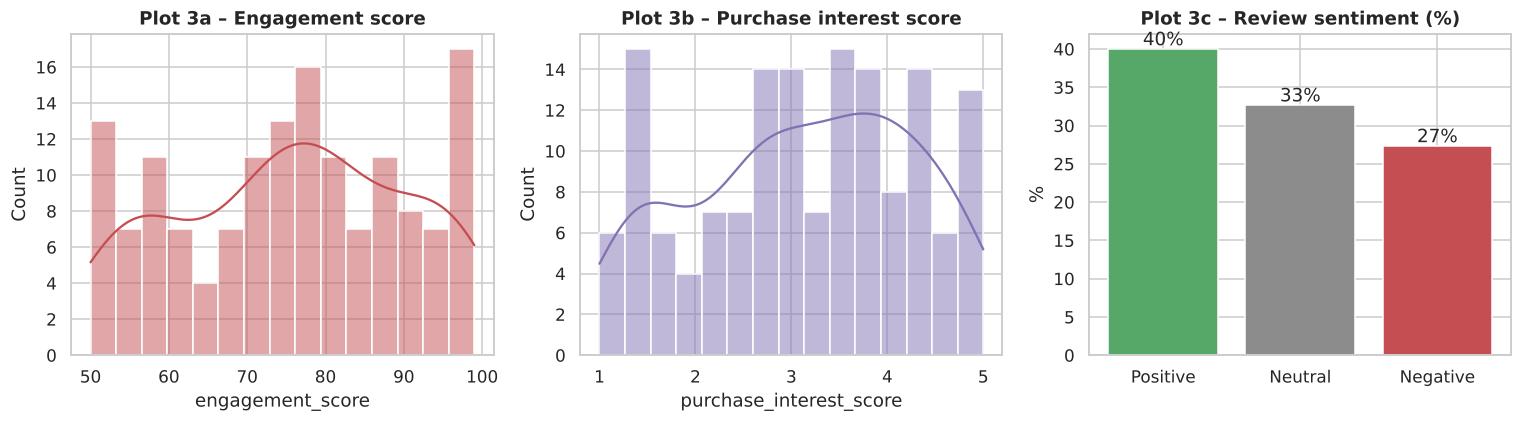

In [10]:
# PLOT 3 – social-media distributions
fig, ax = plt.subplots(1,3, figsize=(14,4))
sns.histplot(s_clean.engagement_score, bins=15, kde=True, ax=ax[0], color='#C44E52'); ax[0].set(title='Plot 3a – Engagement score')
sns.histplot(s_clean.purchase_interest_score, bins=15, kde=True, ax=ax[1], color='#8172B2'); ax[1].set(title='Plot 3b – Purchase interest score')
sent = s_clean.review_sentiment.value_counts(normalize=True).reindex(['Positive','Neutral','Negative'])*100
ax[2].bar(sent.index, sent.values, color=['#55A868','#8C8C8C','#C44E52']); ax[2].set(title='Plot 3c – Review sentiment (%)', ylabel='%')
for i,v in enumerate(sent.values): ax[2].text(i, v+.5, f'{v:.0f}%', ha='center')
plt.tight_layout(); plt.savefig(FIG/'eda3_social.png'); plt.show()

**Interpretation – Plot 3.** Engagement (50–99) and purchase-interest (1–5) are broadly flat/symmetric, not bell-shaped – typical of synthetic or uniformly sampled data. Sentiment is skewed positive (40 % positive, 33 % neutral, 27 % negative), so customers are on average mildly favourable, but 60 % are not clearly positive.

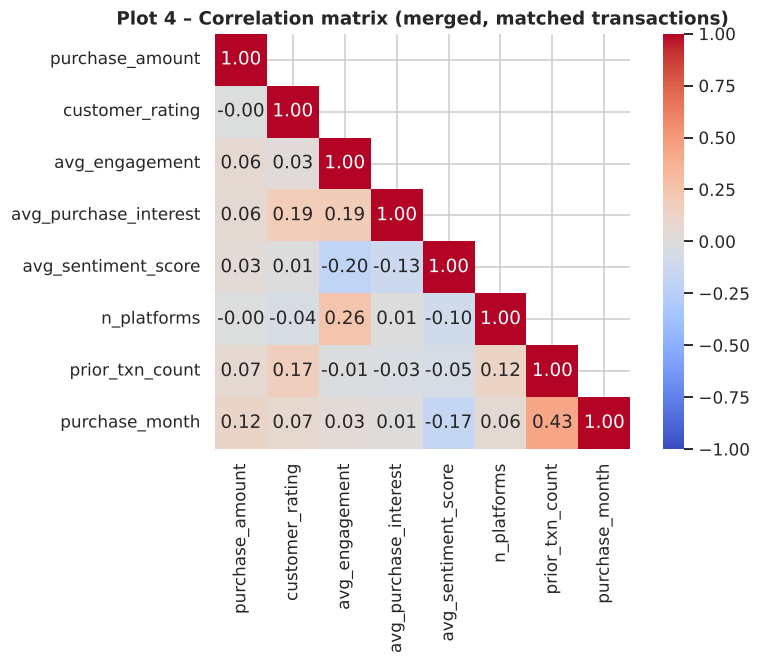

In [11]:
# PLOT 4 – correlation heatmap (post-merge)
corr_cols = ['purchase_amount','customer_rating','avg_engagement','avg_purchase_interest','avg_sentiment_score','n_platforms','prior_txn_count','purchase_month']
c = ready[corr_cols].corr()
plt.figure(figsize=(8,6.2)); sns.heatmap(c, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, mask=np.triu(np.ones_like(c,bool),1))
plt.title('Plot 4 – Correlation matrix (merged, matched transactions)'); plt.tight_layout(); plt.savefig(FIG/'eda4_corr.png'); plt.show()

**Interpretation – Plot 4.** Correlations are weak: the largest is `prior_txn_count` ↔ `purchase_month` (0.43), which is expected – later months mean more accumulated history – so keep only one of them for linear models. Cross-source links are small (e.g. `avg_purchase_interest` ↔ `customer_rating` = 0.19; `avg_engagement` ↔ `avg_sentiment_score` = −0.20), meaning the social and transaction features carry mostly **independent** information (low multicollinearity – good for combining them).

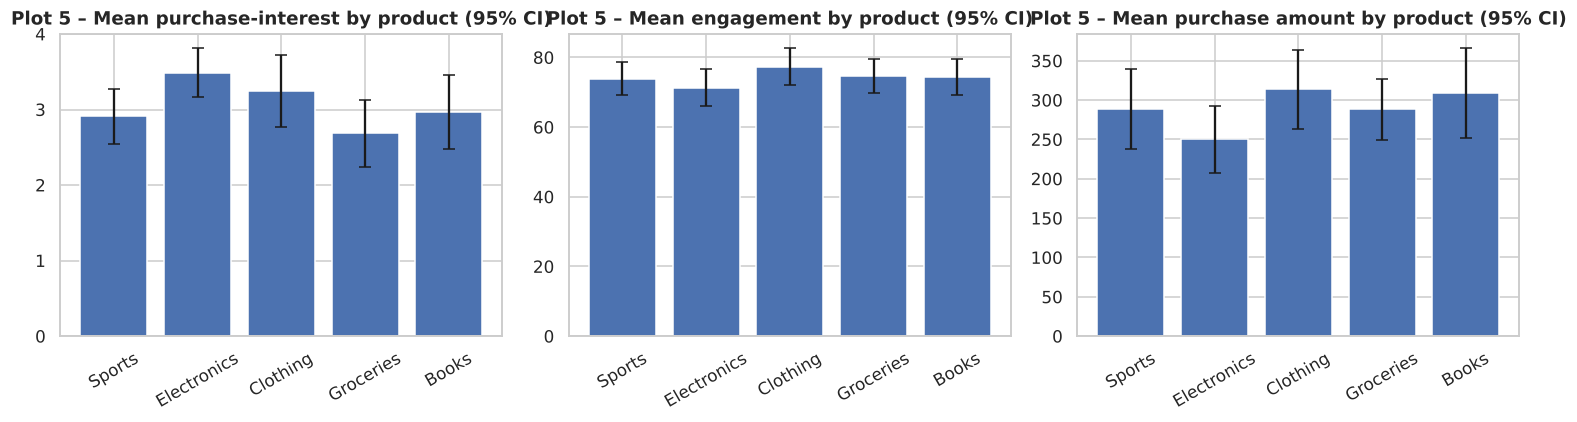

In [12]:
# PLOT 5 – do social features differ by the product bought?
fig, ax = plt.subplots(1,3, figsize=(14,4))
for a, col, ttl in zip(ax, ['avg_purchase_interest','avg_engagement','purchase_amount'], ['Mean purchase-interest','Mean engagement','Mean purchase amount']):
    g = ready.groupby('product_category')[col].agg(['mean','sem']).reindex(order.intersection(ready.product_category.unique()))
    a.bar(g.index, g['mean'], yerr=1.96*g['sem'], capsize=4, color='#4C72B0'); a.tick_params(axis='x', rotation=30)
    a.set(title=f'Plot 5 – {ttl} by product (95% CI)')
plt.tight_layout(); plt.savefig(FIG/'eda5_features_by_target.png'); plt.show()

**Interpretation – Plot 5.** Electronics buyers show the highest average purchase-interest (≈ 3.5) and the lowest purchase amount (≈ 250), and Groceries the lowest interest (≈ 2.7). However, the 95 % confidence intervals overlap almost completely, so these differences are **suggestive, not statistically strong**.

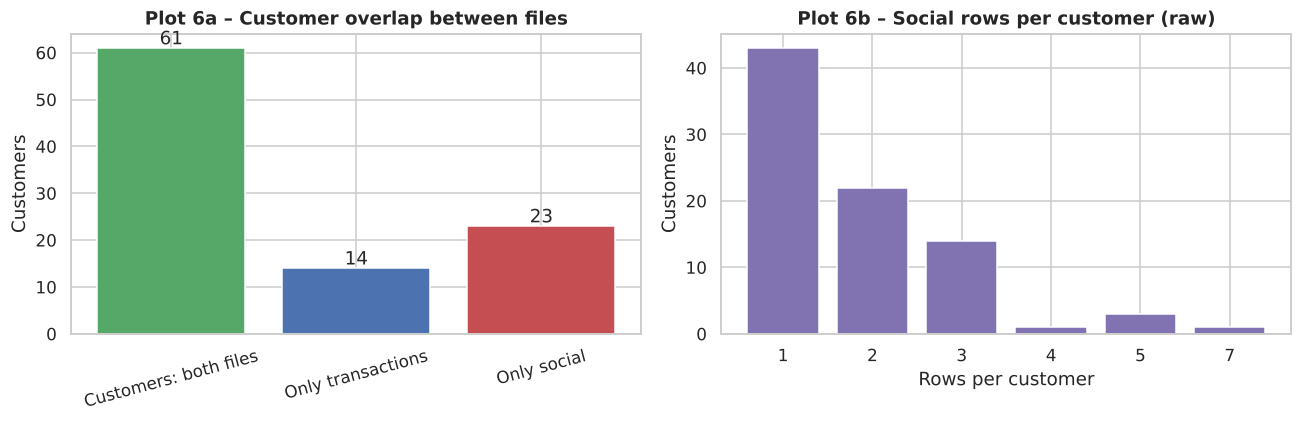

In [13]:
# PLOT 6 – merge coverage + records per customer (justifies aggregation)
fig, ax = plt.subplots(1,2, figsize=(12,4))
cov = pd.Series({'Customers: both files':len(ids_t&ids_s),'Only transactions':len(ids_t-ids_s),'Only social':len(ids_s-ids_t)})
ax[0].bar(cov.index, cov.values, color=['#55A868','#4C72B0','#C44E52']); ax[0].tick_params(axis='x', rotation=15)
for i,v in enumerate(cov.values): ax[0].text(i, v+.8, v, ha='center')
ax[0].set(title='Plot 6a – Customer overlap between files', ylabel='Customers')
rc = raw_s.groupby('customer_id_new').size().value_counts().sort_index()
ax[1].bar(rc.index.astype(str), rc.values, color='#8172B2'); ax[1].set(title='Plot 6b – Social rows per customer (raw)', xlabel='Rows per customer', ylabel='Customers')
plt.tight_layout(); plt.savefig(FIG/'eda6_merge_coverage.png'); plt.show()

**Interpretation – Plot 6.** Only 61 customers are in both files, and 41 of the 84 social customers (≈ 49 %) have two or more rows – direct evidence that the social table must be aggregated before joining. The 14 transaction-only customers (33 transactions) have no social context and are flagged rather than imputed.

## 7. Signal check & modelling notes

In [14]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
ready = pd.read_csv(OUT/'merged_dataset_model_ready.csv'); y = ready.product_category
sets = {
 'Social only (pre-purchase)': (['avg_engagement','avg_purchase_interest','avg_sentiment_score','n_platforms','n_social_records','share_positive','share_negative','engagement_x_interest'], ['top_platform','dominant_sentiment']),
 'Social + history (pre-purchase)': (['avg_engagement','avg_purchase_interest','avg_sentiment_score','n_platforms','prior_txn_count','prior_avg_amount','days_since_prev_txn'], ['top_platform','dominant_sentiment','prev_category']),
 'All incl. amount & rating': (['avg_engagement','avg_purchase_interest','avg_sentiment_score','n_platforms','purchase_amount','customer_rating','purchase_month','prior_txn_count','prior_avg_amount','days_since_prev_txn'], ['top_platform','dominant_sentiment','prev_category'])}
rows=[]
for name,(num,cat) in sets.items():
    ct = make_column_transformer((OneHotEncoder(handle_unknown='ignore'), cat), remainder='passthrough')
    for mname, m in [('Majority baseline', DummyClassifier(strategy='most_frequent')), ('Random Forest', RandomForestClassifier(300, min_samples_leaf=3, random_state=0))]:
        sc = cross_val_score(make_pipeline(ct, m), ready[num+cat], y, groups=ready.customer_id, cv=GroupKFold(5), scoring='accuracy')
        rows.append((name, mname, round(sc.mean(),3), round(sc.std(),3)))
res = pd.DataFrame(rows, columns=['Feature set','Model','Grouped-CV accuracy','± std']); display(res)
print('Chance level for 5 balanced classes ≈ 0.20')

,Feature set,Model,Grouped-CV accuracy,± std
0,Social only (pre-purchase),Majority baseline,0.205,0.050
1,Social only (pre-purchase),Random Forest,0.205,0.075
2,Social + history (pre-purchase),Majority baseline,0.205,0.050
3,Social + history (pre-purchase),Random Forest,0.197,0.078
4,All incl. amount & rating,Majority baseline,0.205,0.050
5,All incl. amount & rating,Random Forest,0.248,0.073


Chance level for 5 balanced classes ≈ 0.20


### What this tells us (read before you build Task 4)
* **Use `GroupKFold` / group-aware splits on `customer_id`.** Social features are identical for every transaction of the same customer; a random row split lets the model memorise a customer and inflates accuracy.
* **Expect modest accuracy.** Accuracy on all feature sets stays close to the 20 % chance level (best ≈ 25 %, within one standard deviation (≈ ±7 pts) of the baseline on only 117 rows). The relationships in this dataset are weak (Plots 4–5), so report **accuracy, macro-F1 and log-loss** honestly and compare against the majority baseline instead of chasing a high number – a well-explained weak result scores better than an unexplained suspicious one.
* **Decide on `purchase_amount` / `customer_rating`.** They are only known after the purchase; for a strict "predict before purchase" system, use the *pre-purchase* sets. Document whichever choice you make.
* The only evaluation set is 117 rows – prefer repeated grouped CV to a single 80/20 split.

## 8. Save outputs

In [15]:
final.to_csv(OUT/'merged_dataset.csv', index=False)
ready_out = final[final.has_social_profile==1].reset_index(drop=True)
ready_out[['prior_avg_amount','prior_avg_rating','days_since_prev_txn']] = ready_out[['prior_avg_amount','prior_avg_rating','days_since_prev_txn']].fillna(0)
ready_out.to_csv(OUT/'merged_dataset_model_ready.csv', index=False)
print('Saved:', (OUT/'merged_dataset.csv').name, final.shape, '|', (OUT/'merged_dataset_model_ready.csv').name, ready_out.shape)

Saved: merged_dataset.csv (150, 31) | merged_dataset_model_ready.csv (117, 31)
